# CS610 Group 1: train the Random Forest model in Colab

Trains a random forest that predicts the hourly Citi Bike rentals per station, in the same way as the team's
Poisson regression and LightGBM notebooks:

- the same features and the same 3 expanding-window validation folds (`utilities/values.py`)
- Optuna tuning on the mean Poisson deviance
- out-of-fold validation predictions for the ensemble, a final model, and test-set predictions

The code and the processed data come from the GitHub repo (branch `feat/poisson-regression`, which has the shared
training code). The random forest model file is written by this notebook, because it is not in the repo yet.

**Runtime:** a random forest runs on the CPU, so a GPU does not help. The default CPU runtime works.
**Runtime → Change runtime type → High-RAM** (Colab Pro) gives more CPU cores, which makes training faster.
With 20 trials, tuning takes about 30-60 minutes on the free runtime.

Run the cells from top to bottom.

## 1. Setup

In [ ]:
# get the repo and the branch with the shared training code (the processed data is already in it)
REPO_URL = 'https://github.com/amelia-lee-smu/CS610-Applied-Machine-Learning.git'
BRANCH = 'feat/poisson-regression'

%cd /content
!rm -rf CS610-Applied-Machine-Learning
!git clone -q --branch {BRANCH} {REPO_URL}
%cd /content/CS610-Applied-Machine-Learning
!git log -1 --format='%h %ad %an: %s' --date=short
!ls data/processed utilities

/content
/content/CS610-Applied-Machine-Learning
4ef5806 2026-10-24 amelia-lee-smu: add poisson regression and common model code
data/processed:
test.parquet  train_validation.parquet

utilities:
poisson_regression.py  preprocessor.py	training.py  utilities.py  values.py


In [ ]:
# Colab already has scikit-learn, pandas and pyarrow; Optuna is the only missing package
!pip install -q optuna

import sklearn
print('scikit-learn', sklearn.__version__)   # needs 1.4 or later (root_mean_squared_error)

scikit-learn 1.6.1


### Random forest model file

Written to `utilities/random_forest.py`, next to the team's other model files. It follows the same interface as
`PoissonRegressionModel` (`fit`, `predict`, `save_model`, `load_model`), so it works with `cross_validate` and
`get_out_of_fold_predictions` in `utilities/training.py`.

In [ ]:
%%writefile utilities/random_forest.py
import pandas as pd
from sklearn import preprocessing
from sklearn.ensemble import RandomForestRegressor

from utilities.training import *
from utilities.utilities import *
from utilities.values import *

# use the team's RANDOM_SEED (feat/lightgbm branch) if values.py has it
RANDOM_SEED = globals().get('RANDOM_SEED', 42)


class RandomForestModel:
    '''
    Preprocessing needed (fitted on only the train set):
        - Station name: converted to a number (ordinal encoded), since the trees need numbers
        - Hour of day and day of week: already numbers, used as they are
        - Numerical features: used as they are (trees split on thresholds, so scaling makes no difference)
    The encoder and model are stored together in this object, so they are saved and loaded together.
    '''
    def __init__(self, n_estimators = 200, max_depth = 20, min_samples_leaf = 5,
                 max_features = 0.5, max_samples = 0.3, criterion = 'poisson', random_state = RANDOM_SEED):
        # hyperparameters (tuned by Optuna)
        self.n_estimators = n_estimators            # number of trees (more = more stable, but slower)
        self.max_depth = max_depth                  # how deep each tree can grow (deeper = more complex)
        self.min_samples_leaf = min_samples_leaf    # fewest rows allowed in a leaf (higher = smoother predictions)
        self.max_features = max_features            # share of features each split may consider (lower = more varied trees)
        self.max_samples = max_samples              # share of the rows each tree is trained on (lower = faster)
        self.criterion = criterion                  # 'poisson' suits count targets; 'squared_error' is the default
        self.random_state = random_state            # fixed so the results are repeatable

        # features used by this model
        self.categorical_cols = CATEGORICAL_COLUMNS    # station is encoded; hour and day are already numbers
        self.numerical_cols = NUMERICAL_COLUMNS        # used as they are
        self.other_cols = OTHER_COLUMNS                # used as they are (0/1 flags)
        self.target_col = NUM_RENTALS

        # encoder and model
        # a station not seen in training is given -1, so prediction still works
        self.station_encoder = preprocessing.OrdinalEncoder(handle_unknown = 'use_encoded_value', unknown_value = -1)
        self.model = RandomForestRegressor(
            n_estimators = self.n_estimators,
            max_depth = self.max_depth,
            min_samples_leaf = self.min_samples_leaf,
            max_features = self.max_features,
            max_samples = self.max_samples,
            criterion = self.criterion,
            random_state = self.random_state,
            n_jobs = -1,    # use every CPU core
        )

    def process_features(self, df):
        features_df = df[self.categorical_cols + self.numerical_cols + self.other_cols].copy()
        features_df[STATION] = self.station_encoder.transform(df[[STATION]]).ravel()
        return features_df

    def fit(self, train_df):
        # fit the encoder and model on the train set
        self.station_encoder.fit(train_df[[STATION]])

        processed_features = self.process_features(train_df)
        self.model.fit(processed_features, train_df[self.target_col])

    def predict(self, test_df):
        processed_features = self.process_features(test_df)
        return self.model.predict(processed_features)

    def feature_importances(self):
        # how much each feature reduced the error across all trees (adds up to 1)
        feature_names = self.categorical_cols + self.numerical_cols + self.other_cols
        return pd.Series(self.model.feature_importances_, index = feature_names).sort_values(ascending = False)

    def save_model(self, file_path):
        # Saves the whole object: encoder, model and settings together
        save_to_pickle_file(self, file_path)

    @staticmethod
    def load_model(file_path):
        # Loads the whole object: encoder, model and settings together
        return read_pickle_file(file_path)


Overwriting utilities/random_forest.py


In [ ]:
import os
import sys
from pathlib import Path

import optuna
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()   # the repo folder
sys.path.append(str(PROJECT_ROOT))

from utilities.random_forest import *
from utilities.training import *
from utilities.utilities import *
from utilities.values import *

data_dir = 'data/'
model_dir = 'models/'

# read the train-validation set (Jan 2020 - Feb 2021)
train_validation_df = read_parquet_file(data_dir + 'processed/train_validation.parquet')
print(f'{len(train_validation_df):,} rows, {os.cpu_count()} CPU cores')

520,149 rows, 2 CPU cores


## 2. Hyperparameter tuning

Each Optuna trial picks a value for every hyperparameter, trains the model on the 3 validation folds,
and returns the mean Poisson deviance (lower is better). <br> Optuna uses the results to pick better values in the next trials.

The test set is not used here.

In [ ]:
def objective(trial):
    # 1. let optuna pick the hyperparams for this trial
    hyperparams = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 200, step = 50),
        'max_depth': trial.suggest_int('max_depth', 8, 30),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 5, 200, log = True),   # search on a log scale
        'max_features': trial.suggest_float('max_features', 0.2, 1.0),
        'max_samples': trial.suggest_float('max_samples', 0.1, 0.4),    # kept small so that training stays fast
        'criterion': trial.suggest_categorical('criterion', ['poisson', 'squared_error']),
    }

    # 2. train a new model with these hyperparams on each validation fold, and score it
    scores_df = cross_validate(RandomForestModel, hyperparams, train_validation_df)
    mean_scores = scores_df[['MAE', 'RMSE', 'poisson_deviance']].mean()

    # Optuna tunes on the Poisson deviance only
    # MAE and RMSE are stored with the trial so they also appear in the results table
    trial.set_user_attr('MAE', mean_scores['MAE'])
    trial.set_user_attr('RMSE', mean_scores['RMSE'])

    # show the scores of this trial
    print('Poisson deviance per fold:', scores_df['poisson_deviance'].round(4).tolist())
    print(f'Trial {trial.number}: mean Poisson deviance = {mean_scores["poisson_deviance"]:.4f}, '
          f'mean MAE = {mean_scores["MAE"]:.4f}, mean RMSE = {mean_scores["RMSE"]:.4f}\n')
    return mean_scores['poisson_deviance']


# hide Optuna's own log line for every trial (the progress bar below shows the progress instead)
optuna.logging.set_verbosity(optuna.logging.WARNING)

# the seed makes the search repeatable
study = optuna.create_study(direction = 'minimize', sampler = optuna.samplers.TPESampler(seed = OPTUNA_SEED))

In [ ]:
n_trials = 20   # lower this (e.g. 5) for a quick run

# the progress bar shows how many trials are done, the time remaining and the best score so far
study.optimize(objective, n_trials = n_trials, show_progress_bar = True)

print('Best hyperparameters:', study.best_params)
print('Best mean Poisson deviance:', round(study.best_value, 4))
print('Mean MAE of the best trial:', round(study.best_trial.user_attrs['MAE'], 4))
print('Mean RMSE of the best trial:', round(study.best_trial.user_attrs['RMSE'], 4))

  0%|          | 0/20 [00:00<?, ?it/s]

Fold 1: training RandomForestModel on 298605 rows
Fold 2: training RandomForestModel on 373269 rows
Fold 3: training RandomForestModel on 447933 rows
Poisson deviance per fold: [1.2926, 0.9926, 0.7302]
Trial 0: mean Poisson deviance = 1.0051, mean MAE = 0.5941, mean RMSE = 0.9710

Fold 1: training RandomForestModel on 298605 rows
Fold 2: training RandomForestModel on 373269 rows
Fold 3: training RandomForestModel on 447933 rows
Poisson deviance per fold: [1.3241, 1.0002, 0.7391]
Trial 1: mean Poisson deviance = 1.0211, mean MAE = 0.6053, mean RMSE = 0.9683

Fold 1: training RandomForestModel on 298605 rows
Fold 2: training RandomForestModel on 373269 rows
Fold 3: training RandomForestModel on 447933 rows
Poisson deviance per fold: [1.2801, 1.0045, 0.755]
Trial 2: mean Poisson deviance = 1.0132, mean MAE = 0.6018, mean RMSE = 0.9716

Fold 1: training RandomForestModel on 298605 rows
Fold 2: training RandomForestModel on 373269 rows
Fold 3: training RandomForestModel on 447933 rows
Poiss

In [ ]:
# all trials, best first
trials_df = study.trials_dataframe()
trials_df.sort_values('value').head(10)

,number,value,datetime_start,datetime_complete,duration,params_criterion,params_max_depth,params_max_features,params_max_samples,params_min_samples_leaf,params_n_estimators,user_attrs_MAE,user_attrs_RMSE,system_attrs_tpe:relative_params:0,state
14,14,0.979811,2026-11-01 08:41:45.263283,2026-11-01 08:49:26.306278,0 days 00:07:41.042995,squared_error,24,0.966348,0.303616,12,200,0.592166,0.974122,"{""criterion"": ""squared_error"", ""max_depth"": 24...",COMPLETE
18,18,0.981205,2026-11-01 09:05:24.125229,2026-11-01 09:12:35.160309,0 days 00:07:11.035080,squared_error,23,0.962314,0.306498,26,200,0.589399,0.970206,"{""criterion"": ""squared_error"", ""max_depth"": 23...",COMPLETE
13,13,0.982163,2026-11-01 08:33:53.667802,2026-11-01 08:41:45.261152,0 days 00:07:51.593350,squared_error,26,0.977937,0.296219,8,200,0.595821,0.975788,"{""criterion"": ""squared_error"", ""max_depth"": 26...",COMPLETE
12,12,0.984441,2026-11-01 08:26:55.474950,2026-11-01 08:33:53.663217,0 days 00:06:58.188267,squared_error,22,0.984774,0.361822,8,150,0.596826,0.980864,"{""criterion"": ""squared_error"", ""max_depth"": 22...",COMPLETE
15,15,0.985320,2026-11-01 08:49:26.308195,2026-11-01 08:53:30.992368,0 days 00:04:04.684173,squared_error,23,0.897938,0.222992,13,150,0.594802,0.970394,"{""criterion"": ""squared_error"", ""max_depth"": 23...",COMPLETE
17,17,0.985461,2026-11-01 08:59:52.989196,2026-11-01 09:05:24.120962,0 days 00:05:31.131766,squared_error,20,0.731682,0.309144,17,200,0.593517,0.967144,"{""criterion"": ""squared_error"", ""max_depth"": 20...",COMPLETE
16,16,0.986084,2026-11-01 08:53:30.994167,2026-11-01 08:59:52.987101,0 days 00:06:21.992934,squared_error,29,0.979324,0.278692,34,200,0.591056,0.970326,"{""criterion"": ""squared_error"", ""max_depth"": 29...",COMPLETE
19,19,0.986128,2026-11-01 09:12:35.162258,2026-11-01 09:17:34.127728,0 days 00:04:58.965470,squared_error,23,0.920050,0.306465,28,150,0.592577,0.971055,"{""criterion"": ""squared_error"", ""max_depth"": 23...",COMPLETE
11,11,0.987583,2026-11-01 08:17:01.335013,2026-11-01 08:26:55.471333,0 days 00:09:54.136320,squared_error,29,0.954321,0.360618,6,200,0.600817,0.985171,"{""criterion"": ""squared_error"", ""max_depth"": 29...",COMPLETE
7,7,0.996667,2026-11-01 08:10:46.504070,2026-11-01 08:12:31.993748,0 days 00:01:45.489678,squared_error,30,0.951599,0.368448,85,50,0.592877,0.975886,NaN,COMPLETE


## 3. Validation predictions (for the ensemble)

- Get the best set of hyperparameters from optuna.
- For each of the cross-validation sets, train the model on the train set, and store the validation set predictions.
- These validation set predictions will be used to train the ensemble model later.

In [ ]:
# get the predictions of each validation fold
fold_results = get_out_of_fold_predictions(RandomForestModel, study.best_params, train_validation_df)

# save the predictions in each file separately
for fold_number, fold_df in enumerate(fold_results, start = 1):
    save_to_parquet_file(fold_df, data_dir + f'predictions/validation_random_forest_fold{fold_number}.parquet')
print('Validation predictions saved.')

Fold 1: training RandomForestModel on 298605 rows


/content/CS610-Applied-Machine-Learning/utilities/training.py:71: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  validation_df[PREDICTION] = model.predict(validation_df)
/content/CS610-Applied-Machine-Learning/utilities/training.py:72: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  validation_df['fold'] = fold_number


Fold 2: training RandomForestModel on 373269 rows


/content/CS610-Applied-Machine-Learning/utilities/training.py:71: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  validation_df[PREDICTION] = model.predict(validation_df)
/content/CS610-Applied-Machine-Learning/utilities/training.py:72: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  validation_df['fold'] = fold_number


Fold 3: training RandomForestModel on 447933 rows


/content/CS610-Applied-Machine-Learning/utilities/training.py:71: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  validation_df[PREDICTION] = model.predict(validation_df)
/content/CS610-Applied-Machine-Learning/utilities/training.py:72: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  validation_df['fold'] = fold_number


Validation predictions saved.


## 4. Final model and test set prediction

In [ ]:
test_df = read_parquet_file(data_dir + 'processed/test.parquet')

# train a new model on the entire train set (Jan 2020 - Feb 2021) using the best hyperparams from Optuna
model = RandomForestModel(**study.best_params)
model.fit(train_validation_df)

# do predictions on the test set (Mar - Apr 2021)
test_df[PREDICTION] = model.predict(test_df)

# save the model and results
model.save_model(model_dir + 'random_forest_model.pkl')
save_to_parquet_file(test_df, data_dir + 'predictions/test_random_forest.parquet')
print('Model and test predictions saved.')
test_df.head()

Model and test predictions saved.


,date,num_rentals,start station name,hour_of_day,day_of_week,num_rentals_t-2,num_rentals_t-3,sine_week_of_year,cosine_week_of_year,temperature_2m,snow_depth,cloud_cover,cloud_cover_mid,relative_humidity_2m,precipitation,wind_speed_10m,is_public_holiday,prediction
0,2021-03-01,0,5 Corners Library,0,0,0.0,0.0,0.812487,0.582979,5.55,0.1,100.0,99.0,96.586780,0.5,10.787993,0,0.040751
1,2021-03-01,0,5 Corners Library,1,0,0.0,0.0,0.812487,0.582979,5.40,0.1,100.0,100.0,97.596886,0.7,12.181624,0,0.037642
2,2021-03-01,0,5 Corners Library,2,0,0.0,0.0,0.812487,0.582979,5.45,0.1,100.0,100.0,97.597850,0.4,9.164103,0,0.020195
3,2021-03-01,0,5 Corners Library,3,0,0.0,0.0,0.812487,0.582979,5.45,0.1,100.0,100.0,97.597850,0.5,6.952755,0,0.019817
4,2021-03-01,0,5 Corners Library,4,0,0.0,0.0,0.812487,0.582979,5.05,0.1,100.0,100.0,98.273410,1.0,8.121970,0,0.025401


## 5. Feature importance

How much each feature reduced the error, summed over all trees (the values add up to 1).
This is calculated on the training data only, so it shows what the model relies on, not how well it predicts.

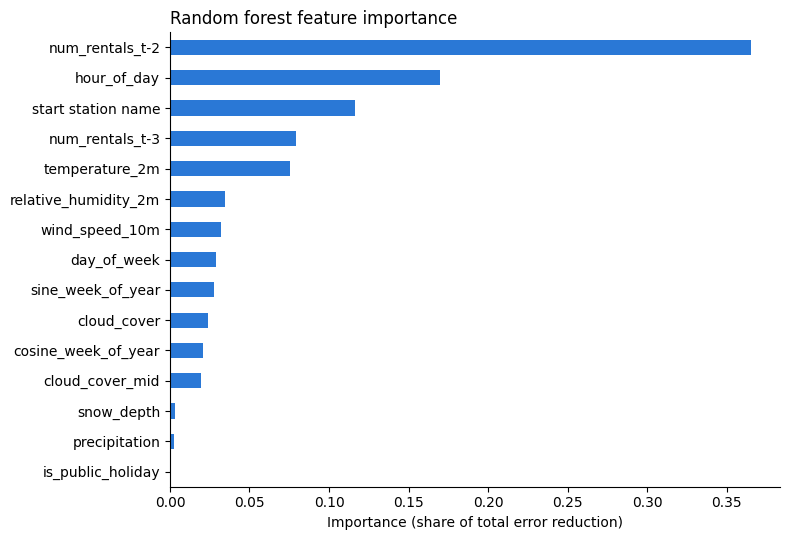

,importance
num_rentals_t-2,0.365
hour_of_day,0.170
start station name,0.117
num_rentals_t-3,0.079
temperature_2m,0.075
relative_humidity_2m,0.034
wind_speed_10m,0.032
day_of_week,0.029
sine_week_of_year,0.028
cloud_cover,0.024


In [ ]:
importances = model.feature_importances()

fig, ax = plt.subplots(figsize = (8, 5.5))
importances.sort_values().plot(kind = 'barh', ax = ax, color = '#2a78d6')
ax.set_xlabel('Importance (share of total error reduction)')
ax.set_title('Random forest feature importance', loc = 'left')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

importances.round(3).to_frame('importance')

## 6. Comparison with the other models (validation folds only)

Compares the out-of-fold predictions of the random forest with the Poisson regression predictions in this branch,
and with the LightGBM and neural network predictions from the `feat/neural-network` branch, on the same validation
periods. The test set is still not used.

In [ ]:
# get the other models' validation predictions from their branch (only the prediction files)
!git fetch -q origin feat/neural-network
!git checkout -q FETCH_HEAD -- data/predictions/ 2>/dev/null || echo 'feat/neural-network branch not found: comparing with Poisson regression only'

from sklearn.metrics import mean_absolute_error, mean_poisson_deviance, root_mean_squared_error

rows = []
for model_name in ['poisson_regression', 'lightgbm', 'neural_network', 'random_forest']:
    for fold_number in range(1, len(VALIDATION_FOLDS) + 1):
        file_path = data_dir + f'predictions/validation_{model_name}_fold{fold_number}.parquet'
        if not Path(file_path).exists():
            continue
        fold_df = read_parquet_file(file_path)
        y_true, y_pred = fold_df[NUM_RENTALS], fold_df[PREDICTION]
        rows.append({
            'model': model_name,
            'fold': fold_number,
            'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': root_mean_squared_error(y_true, y_pred),
            'poisson_deviance': mean_poisson_deviance(y_true, np.clip(y_pred, 1e-8, None)),
        })

comparison_df = pd.DataFrame(rows)
print('Mean over the 3 folds (lower is better):')
display(comparison_df.groupby('model')[['poisson_deviance', 'MAE', 'RMSE']].mean().sort_values('poisson_deviance').round(4))
comparison_df.pivot(index = 'fold', columns = 'model', values = 'poisson_deviance').round(4)

Mean over the 3 folds (lower is better):


,poisson_deviance,MAE,RMSE
model,,,
neural_network,0.8674,0.5318,0.9673
lightgbm,0.8689,0.5323,0.9386
poisson_regression,0.9565,0.5931,0.9776
random_forest,0.9798,0.5922,0.9741


model,lightgbm,neural_network,poisson_regression,random_forest
fold,,,,
1,1.0781,1.0774,1.1984,1.2294
2,0.8908,0.8645,1.0354,0.9782
3,0.6378,0.6603,0.6358,0.7318


## 7. Save the results

Colab deletes its files when the session ends. This saves the model, the predictions and the model file to Google
Drive (`MyDrive/CS610/random_forest/`) and downloads a zip of them to your computer.
Add them to the repo from your own computer (e.g. on a new `feat/random-forest` branch).

In [ ]:
from google.colab import drive, files
drive.mount('/content/drive')

OUT = '/content/drive/MyDrive/CS610/random_forest'
os.makedirs(OUT, exist_ok = True)

outputs = [
    'utilities/random_forest.py',
    'models/random_forest_model.pkl',
    'data/predictions/test_random_forest.parquet',
] + [f'data/predictions/validation_random_forest_fold{n}.parquet' for n in range(1, len(VALIDATION_FOLDS) + 1)]

import shutil, zipfile
with zipfile.ZipFile('/content/random_forest_outputs.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for path in outputs:
        z.write(path)                                   # keeps the repo folder structure inside the zip
        shutil.copy(path, OUT)
print('Saved to', OUT)

files.download('/content/random_forest_outputs.zip')

Mounted at /content/drive
Saved to /content/drive/MyDrive/CS610/random_forest


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>